In [1]:
import numpy as np

# LU-разложение

In [2]:
from nm.linalg import (
    lu_decomposition,
    forward_pass,
    backward_pass,
    determinant,
    inverse_matrix,
)

In [3]:
# Матрица коэффициентов
A = np.array([
    [ 2, -8,  0,  5],
    [-9,  9, -7,  6],
    [-6,  7,  3,  8],
    [-1,  8,  5,  1]
], dtype=np.float32)

# Вектор свободных членов
b = np.array([-40, -58, -75, 1], dtype=np.float32)

**Само разложение**

In [4]:
p, L, U = lu_decomposition(A)
print('p:\n', p, '\n')
print('L:\n', L, '\n')
print('U:\n', U, '\n')

p:
 [1, 3, 2, 0] 

L:
 [[ 1.          0.          0.          0.        ]
 [ 0.11111111  1.          0.          0.        ]
 [ 0.66666667  0.14285714  1.          0.        ]
 [-0.22222222 -0.85714286  0.49651972  1.        ]] 

U:
 [[-9.          9.         -7.          6.        ]
 [ 0.          7.          5.77777778  0.33333333]
 [ 0.          0.          6.84126984  3.95238095]
 [ 0.          0.          0.          4.65661253]] 



Проверка погрешностей:

In [5]:
print(L.dot(U) - A[p])

[[ 0.0000000e+00  0.0000000e+00  0.0000000e+00  0.0000000e+00]
 [ 0.0000000e+00  0.0000000e+00  0.0000000e+00  0.0000000e+00]
 [ 0.0000000e+00  0.0000000e+00  0.0000000e+00  0.0000000e+00]
 [ 0.0000000e+00  0.0000000e+00 -4.1476457e-16  0.0000000e+00]]


**Решение СЛАУ**

In [6]:
z = forward_pass(L, b[p])
x = backward_pass(U, z)
print(x)

[ 7.         3.        -1.9999999 -6.       ]


Невязка:

In [7]:
print(b - A.dot(x))

[ 0.000000e+00  0.000000e+00  0.000000e+00 -9.536743e-07]


**Определитель**

In [8]:
determinant(p, U)

np.float64(-2007.0)

**Обратная матрица**

In [9]:
inv_A = inverse_matrix(p, L, U)
inv_A

array([[ 0.33183857,  0.17488789, -0.39910314,  0.48430493],
       [ 0.09217738,  0.10413553, -0.16641754,  0.24564026],
       [-0.12406577, -0.1509716 ,  0.2077728 , -0.13602392],
       [ 0.21474838,  0.09666168, -0.10662681,  0.19930244]])

Проверка:

In [10]:
errors = np.eye(A.shape[0]) - A.dot(inv_A)
print(errors)

[[ 1.11022302e-16  2.08166817e-16  1.24900090e-16  2.49800181e-16]
 [-4.99600361e-16  0.00000000e+00 -2.49800181e-16 -4.99600361e-16]
 [-4.44089210e-16  1.11022302e-16  0.00000000e+00 -2.22044605e-16]
 [-1.38777878e-16 -4.16333634e-17 -1.24900090e-16  0.00000000e+00]]


In [11]:
print(A.dot(inv_A) - inv_A.dot(A))

[[-3.33066907e-16  6.80011603e-16  2.63677968e-16 -8.32667268e-17]
 [ 5.55111512e-16  1.11022302e-16  2.49800181e-16  5.55111512e-17]
 [ 3.05311332e-16 -1.11022302e-16 -2.22044605e-16  4.16333634e-16]
 [-1.38777878e-16  4.85722573e-16  4.16333634e-17  1.11022302e-16]]


# Метод прогонки

In [12]:
from nm.linalg import thomas_algorithm

In [13]:
A = np.array([
    [  0, -10,  -9],
    [ -5, -21,  -8],
    [  7,  12,   2],
    [  0,   8,   2],
    [  2,  10,   0]
], dtype=float)

b = np.array([7, 29, 31, 56, -24], dtype=float)

In [14]:
thomas_algorithm(A, b)

[np.float64(2.0),
 np.float64(-3.0),
 np.float64(3.0),
 np.float64(8.0),
 np.float64(-4.0)]

# Итерационные методы решения СЛАУ

In [15]:
from scipy.sparse import csr_matrix
import matplotlib.pyplot as plt

A = csr_matrix([
    [21, 1, -8, 4],
    [-9, -23, -2, 4],
    [7, -1, -17, 6],
    [8, 8, -4, -26]
])

b = np.array([-119, 79, -24, -52])

## Метод простых итераций

In [16]:
from nm.linalg import simple_iterations

x = simple_iterations(A, b, precision_epsilon=1e-4, log=True)

print('невязка:')
print(A.dot(x) - b)

невязка:
[-4.07990001e-06 -7.11743870e-05 -5.19554861e-05  1.29858391e-04]


[INFO] Method of Simple Iterations: a priori iteration count estimate is 65
[INFO] Method of Simple Iterations: a posteriori iteration count is 17


Априорная оценка количества итераций $\approx$ 65

Реальное количество итераций = 17

## Метод Зейделя

In [17]:
from nm.linalg import seidel_method

x = seidel_method(A, b, precision_epsilon=1e-4, log=True)

print('невязка:')
print(A.dot(x) - b)

невязка:
[ 2.91224343e-05  5.37251869e-06 -2.04260155e-06  0.00000000e+00]


[INFO] Method of Simple Iterations: a priori iteration count estimate is 65
[INFO] Method of Simple Iterations: a posteriori iteration count is 10


Априорная оценка количества итераций $\approx$ 65

Реальное количество итераций = 10

Видно, что метод Зейделя сходится быстрее, чем метод простых итераций

## Анализ скорости сходимости

In [18]:
precision = np.logspace(start=-2, stop=-14, num=30)

# Замеряем метод простых итераций
si_aprior = []
si_aposterior = []
for pr in precision:
    _, info = simple_iterations(A, b, precision_epsilon=pr, return_estimations=True)
    si_aprior.append(info['aprior'])
    si_aposterior.append(info['aposterior'])

# Замеряем метод Зейделя
sm_aprior = []
sm_aposterior = []
for pr in precision:
    _, info = seidel_method(A, b, precision_epsilon=pr, return_estimations=True)
    sm_aprior.append(info['aprior'])
    sm_aposterior.append(info['aposterior'])

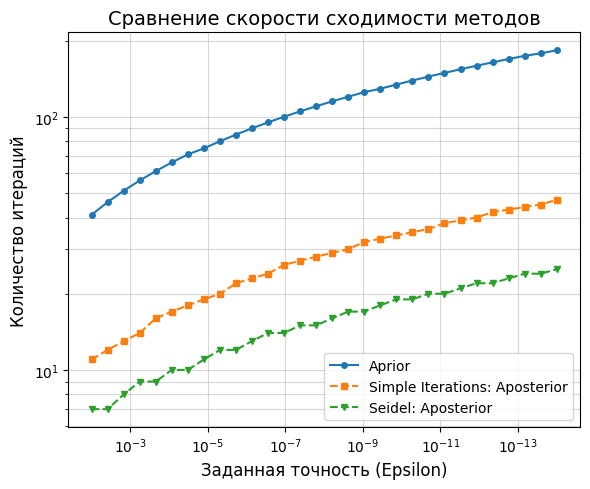

In [19]:
# Настройка стиля
plt.figure(figsize=(6, 5))
plt.grid(True, which="both", ls="-", alpha=0.5)

# Графики для метода простых итераций (Simple Iterations)
plt.loglog(precision, si_aprior, 'o-', label='Aprior', markersize=4)
plt.loglog(precision, si_aposterior, 's--', label='Simple Iterations: Aposterior', markersize=4)

# Графики для метода Зейделя (Seidel Method)
plt.loglog(precision, sm_aposterior, 'v--', label='Seidel: Aposterior', markersize=4)

# Оформление осей и заголовка
plt.gca().invert_xaxis()  # Инвертируем ось X, так как precision идет от 10^-2 до 10^-14
plt.xlabel('Заданная точность (Epsilon)', fontsize=12)
plt.ylabel('Количество итераций', fontsize=12)
plt.title('Сравнение скорости сходимости методов', fontsize=14)
plt.legend(fontsize=10)

plt.tight_layout()
plt.show()

Видно что априорная оценка даёт завышенное количество итераций.

Также видно, что метод Зейделя стабильно сходится быстрее метода простых итераций.

# Метод вращений Якоби

In [20]:
from nm.linalg import eigen_jacobi

A = np.array([
    [-3, -2, -4],
    [-2, -3, -7],
    [-4, -7, -3],
])

val, vec, cnt = eigen_jacobi(A, epsilon=1e-5)
print('Собственные значения:')
print(val)

print('\nСобственные векторы:')
print(vec)

print('\nКоличество итераций до сходимости:')
print(cnt)

print('\nМаксимальная погрешность (Проверка по определению):')
print(np.abs(A.dot(vec) - vec * val).max())

Собственные значения:
[ -1.30641125 -12.02290701   4.32931826]

Собственные векторы:
[[ 0.87397404  0.43007459 -0.22628573]
 [-0.46629413  0.61096553 -0.63975847]
 [-0.13689108  0.664648    0.73450927]]

Количество итераций до сходимости:
7

Максимальная погрешность (Проверка по определению):
5.248814982650174e-08


Видим, что метод корректно вычисляет собственные значения и собственные векторы, причём погрешность вычислений не превосходит заданной точности. 

Проанализируем как увеличивается точность в соответствии с количество итераций

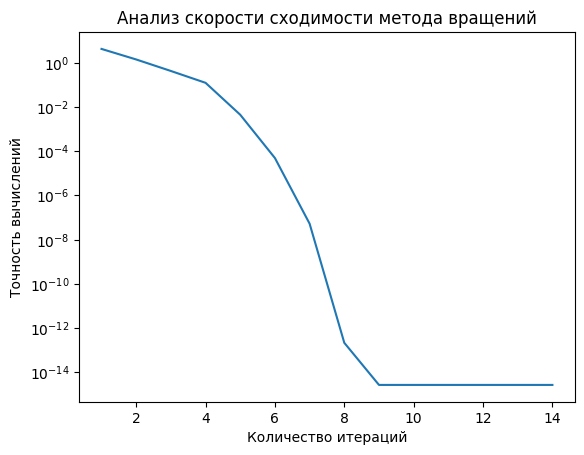

In [24]:
n_iterations = np.arange(start=1, stop=15, step=1)
precisions = []

for n_iter in n_iterations:
    val, vec, cnt = eigen_jacobi(A, n_iter=n_iter)
    pr = np.abs(A.dot(vec) - vec * val).max()
    precisions.append(pr)

plt.semilogy(n_iterations, precisions)
plt.xlabel('Количество итераций')
plt.ylabel('Точность вычислений')
plt.title('Анализ скорости сходимости метода вращений')
plt.show()

Как видно из графика, при маленьком количестве итераций точность растёт медленно.

При среднем количестве итераций точность начинает расти значительно быстрее.

Но начиная с какого-то момента точность упирается в машинный эпсилон, выходит на плато и дальше не растёт.

# QR

In [2]:
A = np.array([
    [7, 6, -3],
    [5, -6, 8],
    [-7, 4, -5]
])

## QR-разложение

In [3]:
from nm.linalg import qr_decomposition

Q, R = qr_decomposition(A)

print('Проверка, что метод отработал верно:')
print(Q.dot(R))

print('\nПогрешность:')
print(np.max(np.abs(Q.dot(R) - A)))

Проверка, что метод отработал верно:
[[ 7.  6. -3.]
 [ 5. -6.  8.]
 [-7.  4. -5.]]

Погрешность:
1.7763568394002505e-15


## QR-алгоритм нахождения собственных значений

In [4]:
from nm.linalg import qr_algorithm

eigen_values = qr_algorithm(A, precision_epsilon=1e-6)
ethalon_values, _ = np.linalg.eig(A)
print('Наши собственные значения:', eigen_values)
print('Эталонные собственные значения:', ethalon_values)

40
Наши собственные значения: [-13.98262585   8.90665239   1.07597346]
Эталонные собственные значения: [-13.98262582   8.90665236   1.07597346]


Алгоритм также работает и для комплексных собственных значений:

In [7]:
# Эта матрица делает растяжение вдоль оси z и поворот в плоскости xOy
# Собственные значения соответственно l1=2, l2=+i, l3=-i
B = np.array([
    [0, -1, 0],
    [1,  0, 0],
    [0,  0, 2]
])

eigen_values = qr_algorithm(B, precision_epsilon=1e-6)
print(eigen_values)

[0.+1.j 0.-1.j 2.+0.j]
